# CareerPilot AI — Phase 3E-2: Job Matcher NLP/ML Engine Development

## 1. Dataset Inspection & Input Preprocessing
We load the **28 curated PII-free development/test cases** (`datasets/benchmark_cases.json`). These are curated development examples — **not** live job listings or human-graded hiring data.


In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

from job_matcher import JobMatcherEngine, SKILL_TAXONOMY, DEFAULT_WEIGHTS
from evaluate_job_matcher import load_benchmark_cases, benchmark_three_models, run_evaluation_suite

# CareerPilot AI Pastel Palette
PASTEL_LAVENDER = "#A78BCE"
PASTEL_BLUE = "#7FB3D5"
PASTEL_GREEN = "#7CC49B"
PASTEL_PINK = "#E295B0"
PASTEL_PEACH = "#E8B794"
CHARCOAL = "#262233"

plt.rcParams["figure.facecolor"] = "#FFFFFF"
plt.rcParams["axes.facecolor"] = "#FBF9FF"
plt.rcParams["axes.edgecolor"] = "#D5C9E8"
plt.rcParams["text.color"] = CHARCOAL
plt.rcParams["axes.labelcolor"] = CHARCOAL
plt.rcParams["xtick.color"] = CHARCOAL
plt.rcParams["ytick.color"] = CHARCOAL

cases = load_benchmark_cases()
tier_counts = {}
for c in cases:
    tier_counts[c["tier"]] = tier_counts.get(c["tier"], 0) + 1
print(f"Total curated test cases: {len(cases)}")
print("Counts by tier:", tier_counts)


Total curated test cases: 28
Counts by tier: {'strong': 4, 'partial': 4, 'weak': 3, 'unrelated': 3, 'paraphrased': 3, 'disambiguation': 4, 'missing_required': 2, 'missing_preferred': 2, 'projects_only': 1, 'invalid_short_jd': 1, 'invalid_empty_profile': 1}


## 2. Three-Way Model Comparison (`all-MiniLM-L6-v2` vs `BAAI/bge-small-en-v1.5` vs `TF-IDF`)
We benchmark all three approaches across `strong`, `partial`, `weak`, `unrelated`, and `paraphrased` cases.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

{
  "all-MiniLM-L6-v2": {
    "load_seconds": 17.939,
    "avg_inference_ms_per_case": 87.76,
    "mean_match_score_by_tier": {
      "paraphrased": 85.67,
      "unrelated": 0.0,
      "partial": 39.0,
      "weak": 0.67,
      "strong": 89.75
    },
    "mean_semantic_sim_by_tier": {
      "paraphrased": 0.6467,
      "unrelated": 0.0253,
      "partial": 0.4198,
      "weak": 0.0968,
      "strong": 0.7572
    },
    "strong_minus_unrelated_score": 89.75,
    "strong_minus_unrelated_semantic": 0.7319,
    "monotonic_tier_ranking": true
  },
  "BAAI/bge-small-en-v1.5": {
    "load_seconds": 2.026,
    "avg_inference_ms_per_case": 292.45,
    "mean_match_score_by_tier": {
      "paraphrased": 92.33,
      "unrelated": 58.67,
      "partial": 62.0,
      "weak": 41.33,
      "strong": 94.0
    },
    "mean_semantic_sim_by_tier": {
      "paraphrased": 0.7229,
      "unrelated": 0.4696,
      "partial": 0.6666,
      "weak": 0.5472,
      "strong": 0.8106
    },
    "strong_minus_unrela

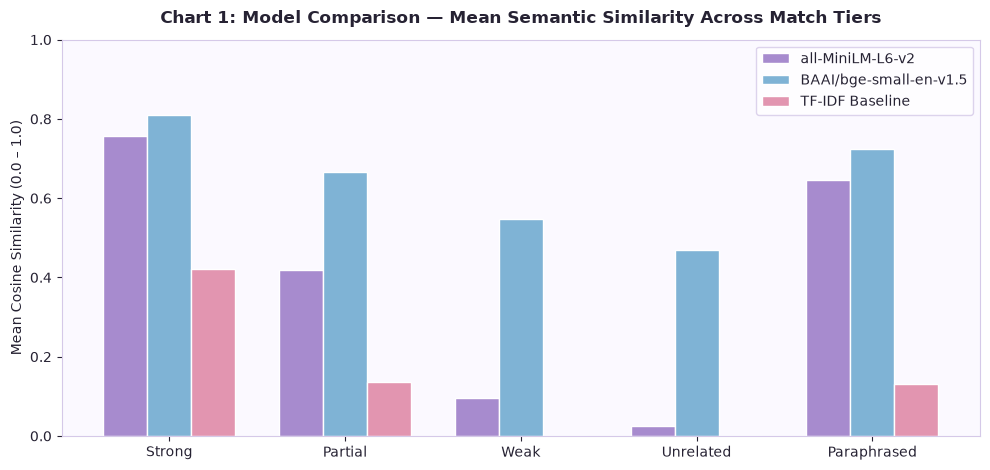

In [2]:
model_comp = benchmark_three_models(cases)
print(json.dumps(model_comp, indent=2))

# Chart 1: Model Comparison Across Match Tiers (Pastel Palette)
tiers = ["strong", "partial", "weak", "unrelated", "paraphrased"]
tier_labels = ["Strong", "Partial", "Weak", "Unrelated", "Paraphrased"]

mini_vals = [model_comp["all-MiniLM-L6-v2"]["mean_semantic_sim_by_tier"][t] for t in tiers]
bge_vals = [model_comp["BAAI/bge-small-en-v1.5"]["mean_semantic_sim_by_tier"][t] for t in tiers]
lex_vals = [model_comp["TF-IDF Baseline"]["mean_semantic_sim_by_tier"][t] for t in tiers]

x = np.arange(len(tiers))
w = 0.25

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(x - w, mini_vals, w, label="all-MiniLM-L6-v2", color=PASTEL_LAVENDER, edgecolor="#FFFFFF")
ax.bar(x, bge_vals, w, label="BAAI/bge-small-en-v1.5", color=PASTEL_BLUE, edgecolor="#FFFFFF")
ax.bar(x + w, lex_vals, w, label="TF-IDF Baseline", color=PASTEL_PINK, edgecolor="#FFFFFF")

ax.set_title("Chart 1: Model Comparison — Mean Semantic Similarity Across Match Tiers", fontweight="bold", pad=12)
ax.set_ylabel("Mean Cosine Similarity (0.0 – 1.0)")
ax.set_ylim(0, 1.0)
ax.set_xticks(x)
ax.set_xticklabels(tier_labels)
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D5C9E8")
plt.tight_layout()
plt.show()


## 3. Skill Extraction, Disambiguation & Required/Preferred Parsing
We verify boundary-aware disambiguation (`Java` vs `JavaScript`, `C` vs `C++`/`CSS3`, `React` vs `React Native`, `SQL` vs `NoSQL`, `Machine Learning` vs `Deep Learning`) and required vs. preferred parsing.


In [3]:
engine = JobMatcherEngine()
print("Selected local model source:", engine.model_source)

for cid in ["jm-18", "jm-19", "jm-20", "jm-21", "jm-24"]:
    c = next(x for x in cases if x["id"] == cid)
    r = engine.match(c["profile"], c["job"])
    print(
        f"{cid} ({c['description']}): score={r['overall_match_score']} | "
        f"detected={r['diagnostics']['user_skills_detected']} | "
        f"missing_req={r['missing_required_skills']} | missing_pref={r['missing_preferred_skills']}"
    )


Selected local model source: D:\CareerPilot AI\ml\JobMatcher\models\all-MiniLM-L6-v2


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

jm-18 (JavaScript profile must NOT match Java requirement): score=0 | detected=['JavaScript', 'CSS3', 'HTML5'] | missing_req=['Java'] | missing_pref=[]
jm-19 (CSS3 & C++ profile must NOT match standalone C requirement): score=14 | detected=['C++', 'CSS3', 'CI/CD'] | missing_req=['C', 'Linux'] | missing_pref=[]


jm-20 (React Native profile must NOT falsely match React web; Node.js normalization): score=55 | detected=['React Native', 'Node.js'] | missing_req=['React'] | missing_pref=[]
jm-21 (NoSQL & Deep Learning vs SQL & Machine Learning): score=16 | detected=['NoSQL', 'Deep Learning'] | missing_req=['Machine Learning', 'SQL'] | missing_pref=[]


jm-24 (100% required skills met, missing preferred Docker/Vitest): score=74 | detected=['JavaScript', 'CSS3', 'HTML5', 'React'] | missing_req=[] | missing_pref=['Docker']


## 4. Matching Dimension Breakdown & Required vs Preferred Skill Coverage
We visualize the 5-dimensional matching breakdown and required vs. preferred skill coverage across representative cases.


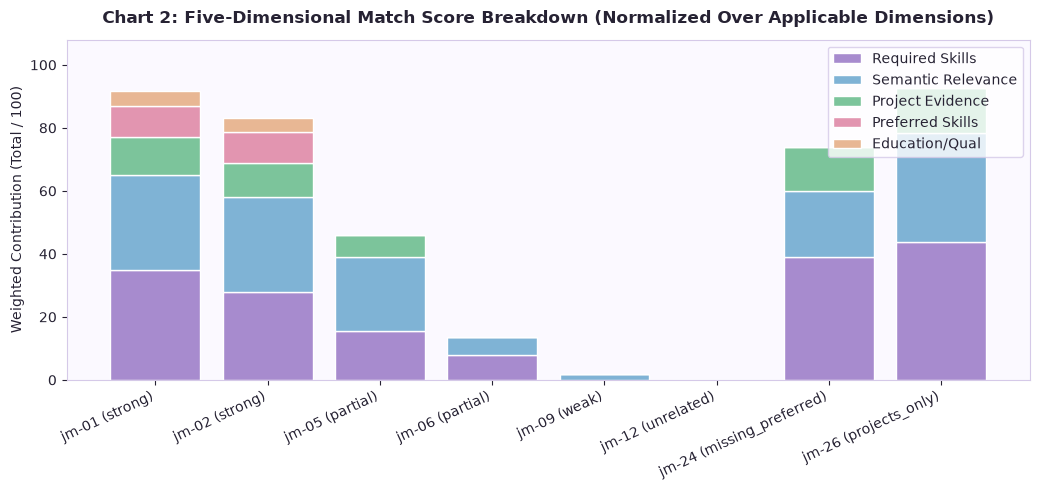

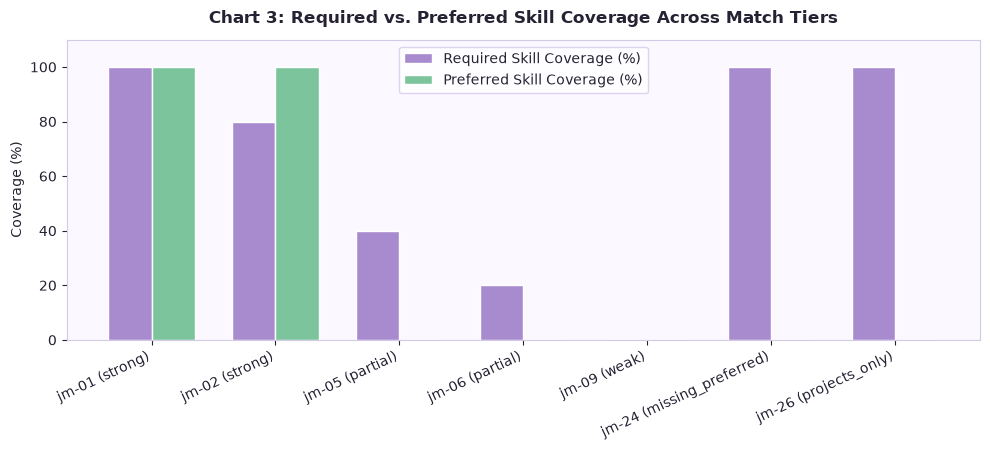

In [4]:
rep_ids = ["jm-01", "jm-02", "jm-05", "jm-06", "jm-09", "jm-12", "jm-24", "jm-26"]
rep_results = []
for cid in rep_ids:
    c = next(x for x in cases if x["id"] == cid)
    rep_results.append((f"{cid} ({c['tier']})", engine.match(c["profile"], c["job"])))

# Chart 2: Matching Dimension Breakdown (Weighted Contribution)
labels = [lbl for lbl, _ in rep_results]
dims = [
    ("required_skill_coverage", "Required Skills", PASTEL_LAVENDER),
    ("semantic_relevance", "Semantic Relevance", PASTEL_BLUE),
    ("project_experience_alignment", "Project Evidence", PASTEL_GREEN),
    ("preferred_skill_coverage", "Preferred Skills", PASTEL_PINK),
    ("education_qualification_alignment", "Education/Qual", PASTEL_PEACH),
]

fig, ax = plt.subplots(figsize=(10.5, 5.0))
bottom = np.zeros(len(rep_results))
for dim_key, dim_label, color in dims:
    contrib = []
    for _, res in rep_results:
        d = res["dimension_scores"][dim_key]
        val = (d["effective_weight"] * d["score_percent"]) if d["applicable"] and d["score_percent"] is not None else 0.0
        contrib.append(val)
    arr = np.array(contrib)
    ax.bar(labels, arr, bottom=bottom, label=dim_label, color=color, edgecolor="#FFFFFF")
    bottom += arr

ax.set_title("Chart 2: Five-Dimensional Match Score Breakdown (Normalized Over Applicable Dimensions)", fontweight="bold", pad=12)
ax.set_ylabel("Weighted Contribution (Total / 100)")
ax.set_ylim(0, 108)
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D5C9E8", loc="upper right")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# Chart 3: Required vs Preferred Skill Coverage
cov_cases = [
    (lbl, res) for lbl, res in rep_results
    if res["required_skill_coverage"] is not None
]
cov_labels = [lbl for lbl, _ in cov_cases]
req_cov = [res["required_skill_coverage"] for _, res in cov_cases]
pref_cov = [res["preferred_skill_coverage"] if res["preferred_skill_coverage"] is not None else 0.0 for _, res in cov_cases]

x2 = np.arange(len(cov_labels))
w2 = 0.35
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(x2 - w2/2, req_cov, w2, label="Required Skill Coverage (%)", color=PASTEL_LAVENDER, edgecolor="#FFFFFF")
ax.bar(x2 + w2/2, pref_cov, w2, label="Preferred Skill Coverage (%)", color=PASTEL_GREEN, edgecolor="#FFFFFF")

ax.set_title("Chart 3: Required vs. Preferred Skill Coverage Across Match Tiers", fontweight="bold", pad=12)
ax.set_ylabel("Coverage (%)")
ax.set_ylim(0, 110)
ax.set_xticks(x2)
ax.set_xticklabels(cov_labels, rotation=25, ha="right")
ax.legend(frameon=True, facecolor="#FFFFFF", edgecolor="#D5C9E8")
plt.tight_layout()
plt.show()


## 5. Evaluation Suite, Error Analysis & Artifact Verification
We run `run_evaluation_suite()` across all 28 curated cases and verify saved artifacts in `artifacts/` and `models/`.


In [5]:
eval_report = run_evaluation_suite(engine, cases)
print("Evaluation passed:", eval_report["all_assertions_passed"], "| Total cases:", eval_report["total_cases"])
print("Sensitivity check (jm-23 adding Docker):", eval_report["sensitivity_check_jm23"])
print("Artifacts:", [p.name for p in sorted(Path("artifacts").glob("*.json"))])
print("Saved local models:", [p.name for p in sorted(Path("models").iterdir())])


Evaluation passed: True | Total cases: 28
Sensitivity check (jm-23 adding Docker): {'without_docker_score': 91, 'with_docker_score': 95}
Artifacts: ['evaluation_report.json', 'model_comparison.json', 'scoring_config.json', 'skill_taxonomy.json']
Saved local models: ['all-MiniLM-L6-v2']
